In [23]:
import math 
import random 
import re 
from collections import Counter, defaultdict 
from typing import List, Dict, Tuple 
import numpy as np 
import matplotlib.pyplot as plt 

import torch 
import torch.nn as nn
import torch.nn.functional as F 

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)


In [24]:
def simple_tokenize(text: str) -> List[str]:
    text = text.lower()
    text = re.sub(r"[^a-z0-9']+", " ", text)
    return text.split()
def sentence_split(paragraph: str) -> List[List[str]]:
    parts = re.split(r"[.!?]+", paragraph)
    sents = [simple_tokenize(p) for p in parts]
    return [s for s in sents if s ]
def plot_bar(labels, values, title , ylabel = None):
    plt.figure(figsize = (7,4))
    plt.bar(labels, values)
    plt.title(title) 
    if ylabel:
        plt.ylabel(ylabel)
    plt.xticks(rotation = 45, ha = 'right')
    plt.tight_layout()
    plt.show()
def plot_heatmap(matrix, xlabels, ylabels, title):
    plt.figure(figsize = (6,5))
    plt.imshow(matrix, aspect = "auto")
    plt.title(title)
    plt.xticks(ticks = np.arange(len(xlabels)), labels = xlabels, rotation = 45, ha = 'right')
    plt.yticks(ticks = np.arange(len(ylabels)), labels = ylabels) 
    plt.colorbar()
    plt.tight_layout()
    plt.show()
def pca_2d(X: np.ndarray, n_components = 2) -> np.ndarray:
    Xc = X - X.mean(axis = 0, keedpdims = True)
    U, S, Vt = np.linalg.svd(Xc, full_matrices = False)
    return (U[:, :n_components] * S[:n_components])



In [25]:
demo_text = """
The king rules the kingdom. The queen is wise and kind.
A man and a woman walk to the market. The market sells apples and bread.
The chef cooked tasty food quickly. The cook prepares delicious meals.
NLP models learn word embeddings. Word embeddings capture meaning.
Cats chase mice. Dogs chase cats. Animals live in the kingdom.
The baker bakes bread daily. The king and the queen visit the market.
Language models predict the next word. Embeddings map words to vectors.
"""
sents = sentence_split(demo_text)
tokens = [t for s in sents for t in s] 
print(tokens)
#Vocab building without no <unk> 
min_freq = 1 
freqs = Counter(tokens)
print(freqs)
itos = sorted([w for w,c in freqs.items() if c >= min_freq])
print(itos)
stoi = {w:i for i , w in enumerate(itos)}
print(stoi)
v = len(itos)
print(f"Vocab size: {v}")

['the', 'king', 'rules', 'the', 'kingdom', 'the', 'queen', 'is', 'wise', 'and', 'kind', 'a', 'man', 'and', 'a', 'woman', 'walk', 'to', 'the', 'market', 'the', 'market', 'sells', 'apples', 'and', 'bread', 'the', 'chef', 'cooked', 'tasty', 'food', 'quickly', 'the', 'cook', 'prepares', 'delicious', 'meals', 'nlp', 'models', 'learn', 'word', 'embeddings', 'word', 'embeddings', 'capture', 'meaning', 'cats', 'chase', 'mice', 'dogs', 'chase', 'cats', 'animals', 'live', 'in', 'the', 'kingdom', 'the', 'baker', 'bakes', 'bread', 'daily', 'the', 'king', 'and', 'the', 'queen', 'visit', 'the', 'market', 'language', 'models', 'predict', 'the', 'next', 'word', 'embeddings', 'map', 'words', 'to', 'vectors']
Counter({'the': 13, 'and': 4, 'market': 3, 'word': 3, 'embeddings': 3, 'king': 2, 'kingdom': 2, 'queen': 2, 'a': 2, 'to': 2, 'bread': 2, 'models': 2, 'cats': 2, 'chase': 2, 'rules': 1, 'is': 1, 'wise': 1, 'kind': 1, 'man': 1, 'woman': 1, 'walk': 1, 'sells': 1, 'apples': 1, 'chef': 1, 'cooked': 1, '

In [26]:
window_size = 2 
def build_cbow_pairs(sents, window = 2) -> List[Tuple[List[int], int]]:
    pairs = []
    for sent in sents:
        ids = [stoi[w] for w in sent if w in stoi]
        for i in range(len(ids)):
            left = max(0, i - window)
            right = min(len(ids), i + window + 1) 
            ctx = [ids[j] for j in range(left , right) if j != i] #ids = [0,1,2,3,4]
            #ctx = [0,1,3,4]  # i = 2
            if ctx:
                pairs.append((ctx, ids[i])) # ([0, 1, 3, 4], 2)
    return pairs
def build_skipgram_pairs(sents, window = 2) -> List[Tuple[int, int]]:
    pairs = []
    for sent in sents:
        ids = [stoi[w]for w in sent if w in stoi] 
        for i in range(len(ids)):
            left = max(0, i-window)
            right = min(len(ids), i + window + 1)
            for j in range(left, right):
                if j != i:
                    pairs.append((ids[i], ids[j])) # (2, 0), (2, 1), (2, 3), (2, 4)
    return pairs
cbow_pairs = build_cbow_pairs(sents, window = window_size)
sg_pairs = build_skipgram_pairs(sents, window = window_size)
print("CBOW pairs:", len(cbow_pairs))
print("Skip-gram pairs:", len(sg_pairs))

CBOW pairs: 81
Skip-gram pairs: 234


In [27]:
cbow_pairs[0]

       

([21, 39], 42)

In [28]:
sg_pairs[0]

(42, 21)

# Negative sampling

In [29]:
pow_freq = np.array([freqs[w] for w in itos], dtype = np.float64) ** 0.75
unigram = pow_freq / pow_freq.sum()

def sample_negatives(batch_size: int, k: int) -> np.ndarray:
    return np.random.choice(v, size = (batch_size, k), p = unigram)
     #np.random.choice(0,1,2,3,4, size = (eows, columns), p = unigram)

In [45]:
class CBOWNeg(nn.Module):
    def __init__(self, vocab_size, emb_dim = 64):
        super().__init__()
        self.in_emb = nn.Embedding(vocab_size, emb_dim)
        self.out_emb = nn.Embedding(vocab_size, emb_dim)
        self.out_emb = nn.Embedding(vocab_size, emb_dim)  
        #To keep Training Stable 
        nn.init.uniform_(self.in_emb.weight, -0.5/emb_dim, 0.5/emb_dim)
        nn.init.uniform_(self.out_emb.weight, -0.5/emb_dim, 0.5/emb_dim)
    def forward(self, contexts, targets, negs): 
        B = len(contexts)
        K = negs.shape[1] 
        maxl = max(len(c) for c in contexts)
        ctx_ids = torch.full((B, maxl), fill_value = 0, dtype = torch.long)
        mask = torch.zeros(B, maxl, dtype = torch.float32)
        for i, c in enumerate(contexts):
            ctx_ids[i, :len(c)] = torch.tensor(c, dtype = torch.long)
            mask[i, :len(c)] = 1.0 
        # For each and every word it will consider Number list 
        ctx_vecs = self.in_emb(ctx_ids)
        ctx_vecs = (ctx_vecs * mask.unsqueeze(-1)).sum(1) # it will mask with 1 and 0 
        ctx_vecs = ctx_vecs / (mask.sum(1, keepdim = True) + 1e-9) 
        #calculating positive score 
        pos_vecs = self.in_emb(targets)
        pos_score = (ctx_vecs * pos_vecs).sum(-1)
        poss_loss = F.binary_cross_entropy_with_logits(pos_score, torch.ones_like(pos_score))


        #Calculating negative score 
        neg_vecs = self.out_emb(negs)
        neg_score =  torch.einsum("bd,bkd->bk", ctx_vecs, neg_vecs)
        neg_loss = F.binary_cross_entropy_with_logits(neg_score, torch.zeros_like(neg_score))
        return poss_loss + neg_loss 
def batchify_cbow(pairs, bs = 64):
        
        idx = np.arange(len(pairs))
        np.random.shuffle(idx)
        for i in range(0, len(pairs), bs):
            chunk = idx[i:i+bs]
            contexts  = [pairs[j][0] for j in chunk]
            targets = torch.tensor([pairs[j][1] for j in chunk], dtype = torch.long)
            yield contexts, targets 




        


        

Epoch 1: loss = 1.3861
Epoch 2: loss = 1.3845
Epoch 3: loss = 1.3810
Epoch 4: loss = 1.3753
Epoch 5: loss = 1.3662
Epoch 6: loss = 1.3560
Epoch 7: loss = 1.3425
Epoch 8: loss = 1.3250


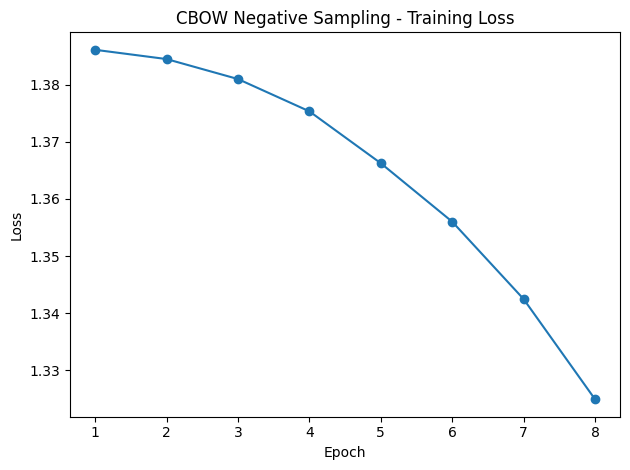

In [47]:
cbow = CBOWNeg(v, emb_dim = 64)
opt = torch.optim.Adam(cbow.parameters(), lr = 3e-3)
epochs = 8 
k = 5 
loss_curve = []
for ep in range(1, epochs +1):
    cbow.train()
    total = 0.0 
    steps = 0 
    for contexts, targets in batchify_cbow(cbow_pairs, bs = 64):
        negs_np = sample_negatives(len(targets), k) 
        negs = torch.from_numpy(negs_np).long()
        loss = cbow(contexts, targets, negs) 
        opt.zero_grad()
        loss.backward()
        opt.step() 
        total += loss.item()
        steps += 1 
    avg = total / max(1, steps)
    loss_curve.append(avg)
    print(f"Epoch {ep}: loss = {avg:.4f}") 

plt.plot(range(1, epochs+1), loss_curve, marker='o')
plt.title("CBOW Negative Sampling - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.tight_layout()
plt.show()      



# Skip-gram

In [53]:
class SGNS(nn.Module):
    def __init__(self, vocab_size, emb_dim = 64):
        super().__init__()
        self.in_emb = nn.Embedding(vocab_size, emb_dim) #center
        self.out_emb = nn.Embedding(vocab_size, emb_dim) #context  
        nn.init.uniform_(self.in_emb.weight, -0.5/emb_dim, 0.5/emb_dim)
        nn.init.uniform_(self.out_emb.weight, -0.5/emb_dim, 0.5/emb_dim)
    def forward(self, centers, contexts, negs):
        cen_vec = self.in_emb(centers)
        pos_vec = self.out_emb(contexts)
        pos_score = (cen_vec * pos_vec).sum(-1)
        pos_loss = F.binary_cross_entropy_with_logits(pos_score, torch.ones_like(pos_score))

        neg_vec = self.out_emb(negs)
        neg_score = torch.einsum("bd,bkd->bk", cen_vec, neg_vec)
        neg_loss = F.binary_cross_entropy_with_logits(neg_score, torch.zeros_like(neg_score))
        return pos_loss + neg_loss 
def batchify_sg(pairs, bs = 128):
    idx = np.arange(len(pairs)) 
    np.random.shuffle(idx)
    for i in range(0, len(idx), bs):
        chunk = idx[i:i+bs]
        centers = torch.tensor([pairs[j][0] for j in chunk], dtype = torch.long)
        contexts = torch.tensor([pairs[j][1] for j in chunk], dtype = torch.long)
        yield centers, contexts 
        

Skip-gram Epoch 1: loss = 1.3863
Skip-gram Epoch 2: loss = 1.3851
Skip-gram Epoch 3: loss = 1.3829
Skip-gram Epoch 4: loss = 1.3784
Skip-gram Epoch 5: loss = 1.3725
Skip-gram Epoch 6: loss = 1.3638


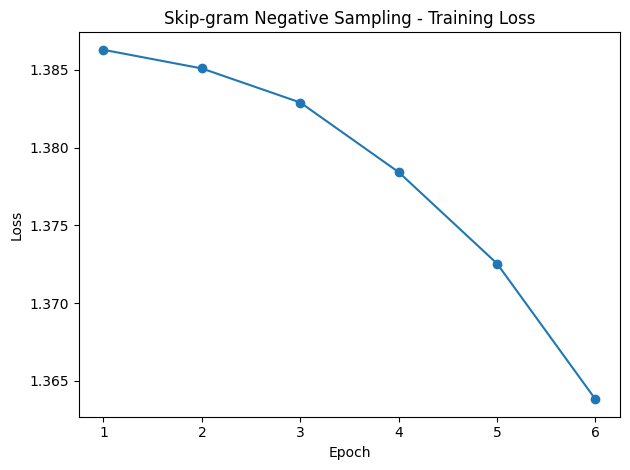

In [55]:
sg = SGNS(v, emb_dim = 64)
opt = torch.optim.Adam(sg.parameters(), lr = 3e-3)
epochs = 6 
k = 5 
loss_curve = []
for ep in range(1, epochs + 1):
    sg.train()
    total = 0.0 
    steps = 0 
    for centers, contexts in batchify_sg(sg_pairs, bs = 64):
        negs_np = sample_negatives(len(centers), k) 
        negs = torch.from_numpy(negs_np).long() 
        loss = sg(centers, contexts, negs)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item()
        steps += 1 
    average = total / max(1, steps)
    loss_curve.append(average)
    print(f"Skip-gram Epoch {ep}: loss = {average:.4f}")
plt.plot(range(1, epochs+1), loss_curve, marker = 'o')
plt.title("Skip-gram Negative Sampling - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.tight_layout()
plt.show()